# 07 - Evaluacion comparativa de detectores

Comparacion de Faster R-CNN + MobileNetV3, YOLO11n y RF-DETR Nano sobre las 8.113 ventanas positivas de validacion, utilizando las mismas metricas

## Preparar el entorno

In [3]:
%pip -q install "ultralytics==8.4.207" "rfdetr==1.12.0" "kagglehub==1.0.3" "torchmetrics[detection]>=1.4,<2" "pycocotools>=2.0.7"

In [4]:
from pathlib import Path
from PIL import Image
from google.colab import drive
import gc
import json
import zipfile
import kagglehub
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from ultralytics import YOLO
from collections import Counter
from rfdetr import RFDETRNano
from torchmetrics.detection.mean_ap import MeanAveragePrecision
import hashlib

drive.mount("/content/drive")
BASE_LOCAL = Path("/content/proyecto_aves")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_E1 = BASE_DRIVE / "experiments/detector/E1_FasterRCNN_MobileNetV3/entrenamiento_final_v1"
DIR_E2 = BASE_DRIVE / "experiments/detector/E2_YOLO11n/final_v1"
DIR_E3 = BASE_DRIVE / "experiments/detector/E3_RFDETR_Nano/final_v1"
DIR_E7 = BASE_DRIVE / "experiments/detector/E4_Comparacion_v1"
DIR_DATOS = BASE_LOCAL / "comparacion_detectores"
DIR_PRED = DIR_E7 / "predicciones"
for carpeta in (DIR_DATOS, DIR_PRED):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Resultados:", DIR_E7)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1


## Preparar validación

In [ ]:
NOTEBOOK_KAGGLE = "santiagocorrea802/notebook1240c3d28f/versions/1"
PARTES = {13: 858, 14: 3000, 15: 3000, 16: 1255}

for i, esperado in PARTES.items():
    nombre = f"yolo11n_completo_parte_{i:02d}"
    carpeta = DIR_DATOS / nombre
    imagenes = carpeta / "images/val"
    if len(list(imagenes.glob("*.png"))) == esperado:
        print(f"Parte {i:02d}/16 disponible")
        continue

    archivo = DIR_DATOS / f"{nombre}.zip"
    if archivo.is_file() and not zipfile.is_zipfile(archivo):
        archivo.unlink()
    if not archivo.is_file():
        archivo = Path(kagglehub.notebook_output_download(NOTEBOOK_KAGGLE, path=archivo.name, output_dir=str(DIR_DATOS)))

    with zipfile.ZipFile(archivo) as z:
        rutas = [Path(info.filename) for info in z.infolist() if not info.is_dir()]
        z.extractall(DIR_DATOS if all(p.parts[0] == nombre for p in rutas) else carpeta)

    archivo.unlink()
    print(f"Parte {i:02d}/16 preparada")

100%|██████████| 1.14G/1.14G [00:55<00:00, 22.3MB/s]


Parte 13/16 preparada


100%|██████████| 1.14G/1.14G [00:59<00:00, 20.6MB/s]


Parte 14/16 preparada


100%|██████████| 1.14G/1.14G [01:29<00:00, 13.7MB/s]


Parte 15/16 preparada


100%|██████████| 489M/489M [00:26<00:00, 19.4MB/s]


Parte 16/16 preparada


In [ ]:
RUTAS = sorted(p for i in PARTES for p in (DIR_DATOS / f"yolo11n_completo_parte_{i:02d}" / "images/val").glob("*.png"))
if len(RUTAS) != 8113:
    raise ValueError(f"Ventanas encontradas: {len(RUTAS)}")

def cargar_etiquetas(ruta):
    etiqueta = ruta.parents[2] / "labels/val" / f"{ruta.stem}.txt"
    datos = np.loadtxt(etiqueta, dtype=np.float32, ndmin=2)
    xywh = datos[:, 1:5]
    cajas = np.column_stack((xywh[:, 0] - xywh[:, 2] / 2, xywh[:, 1] - xywh[:, 3] / 2,
                             xywh[:, 0] + xywh[:, 2] / 2, xywh[:, 1] + xywh[:, 3] / 2))
    return {"boxes": torch.from_numpy(cajas.astype(np.float32)), "labels": torch.ones(len(cajas), dtype=torch.int64)}

OBJETIVOS = [cargar_etiquetas(ruta) for ruta in tqdm(RUTAS, desc="Etiquetas")]
print("Ventanas:", len(RUTAS))
print("Anotaciones:", sum(len(x["boxes"]) for x in OBJETIVOS))

Etiquetas:   0%|          | 0/8113 [00:00<?, ?it/s]

Ventanas: 8113
Anotaciones: 20419


## Obtener predicciones

In [ ]:

RUTA_E1 = DIR_E1 / "evaluacion_gpu_v1/predicciones_validation_positivas.pt"
payload = torch.load(RUTA_E1, map_location="cpu", weights_only=True)
registros = payload["predicciones"]
checkpoint = torch.load(DIR_E1 / "best.pt", map_location="cpu", weights_only=True)

if abs(float(checkpoint["ap50"]) - float(payload["ap50_checkpoint"])) > 1e-4:
    raise ValueError("Las predicciones E1 no corresponden a best.pt")

escala = torch.tensor([997, 513, 997, 513], dtype=torch.float32)

def invertir(cajas):
    resultado = cajas.clone()
    resultado[:, 1] = 1 - cajas[:, 3]
    resultado[:, 3] = 1 - cajas[:, 1]
    return resultado

PRED_E1 = [
    {"boxes": invertir(r["boxes"].float() / escala), "scores": r["scores"].float()}
    for r in registros
]

GT_E1 = [
    {"boxes": invertir(r["gt_boxes"].float() / escala), "labels": torch.ones(len(r["gt_boxes"]), dtype=torch.int64)}
    for r in registros
]

print("Ventanas Faster R-CNN:", len(PRED_E1))
print("Anotaciones Faster R-CNN:", sum(len(x["boxes"]) for x in GT_E1))

del payload, registros, checkpoint


Ventanas Faster R-CNN: 8113
Anotaciones Faster R-CNN: 20419


In [ ]:
BLOQUE = 128
CONF_MIN = 0.05
MAX_DETECCIONES = 100

def hash_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

h = hashlib.sha256()
for ruta in RUTAS:
    h.update(str(ruta.relative_to(DIR_DATOS)).encode("utf-8"))
    h.update((ruta.parents[2] / "labels/val" / f"{ruta.stem}.txt").read_bytes())

protocolo = {
    "dataset": NOTEBOOK_KAGGLE,
    "anotaciones": h.hexdigest(),
    "faster_rcnn": hash_archivo(RUTA_E1),
    "faster_rcnn_best": hash_archivo(DIR_E1 / "best.pt"),
    "yolo11n": hash_archivo(DIR_E2 / "best_ap50.pt"),
    "rfdetr": hash_archivo(DIR_E3 / "checkpoint_best_total.pth"),
    "conf_min": CONF_MIN,
    "max_detecciones": MAX_DETECCIONES,
    "yolo_imgsz": 640,
    "yolo_nms_iou": 0.7,
    "rfdetr_config": json.loads((DIR_E3 / "configuracion.json").read_text(encoding="utf-8"))
}

ID_EVALUACION = hashlib.sha256(json.dumps(protocolo, sort_keys=True).encode("utf-8")).hexdigest()[:16]
DIR_PRED = DIR_E7 / "predicciones" / ID_EVALUACION
DIR_PRED.mkdir(parents=True, exist_ok=True)
(DIR_PRED / "protocolo.json").write_text(json.dumps(protocolo, indent=2), encoding="utf-8")

def ruta_bloque(nombre, inicio):
    carpeta = DIR_PRED / nombre
    carpeta.mkdir(parents=True, exist_ok=True)
    return carpeta / f"{inicio:05d}.pt"

def cargar_predicciones(nombre):
    salidas = []
    for inicio in range(0, len(RUTAS), BLOQUE):
        salidas.extend(torch.load(ruta_bloque(nombre, inicio), map_location="cpu", weights_only=True))
    return salidas

print("Evaluacion:", ID_EVALUACION)

Evaluacion: 14851be08eb33c92


In [ ]:
modelo = YOLO(str(DIR_E2 / "best_ap50.pt"))
for inicio in tqdm(range(0, len(RUTAS), BLOQUE), desc="YOLO11n"):
    archivo = ruta_bloque("yolo11n", inicio)
    if archivo.is_file():
        continue

    rutas = RUTAS[inicio:inicio + BLOQUE]
    predicciones = []
    salidas = modelo.predict(source=[str(p) for p in rutas], imgsz=640, conf=CONF_MIN, iou=0.7,
                             max_det=MAX_DETECCIONES, batch=8, verbose=False, stream=True)
    for resultado in salidas:
        alto, ancho = resultado.orig_shape
        escala = np.asarray([ancho, alto, ancho, alto], dtype=np.float32)
        cajas = resultado.boxes.xyxy.cpu().numpy() / escala
        predicciones.append({"boxes": torch.from_numpy(cajas.astype(np.float32)), "scores": resultado.boxes.conf.float().cpu()})

    temporal = archivo.with_suffix(".tmp")
    torch.save(predicciones, temporal)
    temporal.replace(archivo)

print("Predicciones YOLO11n completas")
del modelo
gc.collect()

YOLO11n:   0%|          | 0/64 [00:00<?, ?it/s]

Predicciones YOLO11n completas


3412

In [ ]:
configuracion = json.loads((DIR_E3 / "configuracion.json").read_text(encoding="utf-8"))
modelo = RFDETRNano(pretrain_weights=str(DIR_E3 / "checkpoint_best_total.pth"), num_classes=1, resolution=int(configuracion["resolution"]))
for inicio in tqdm(range(0, len(RUTAS), BLOQUE), desc="RF-DETR Nano"):
    archivo = ruta_bloque("rfdetr_nano", inicio)
    if archivo.is_file():
        continue

    predicciones = []
    for j in range(inicio, min(inicio + BLOQUE, len(RUTAS)), 2):
        imagenes = []
        for ruta in RUTAS[j:min(j + 2, len(RUTAS))]:
            with Image.open(ruta) as imagen:
                imagenes.append(imagen.convert("RGB"))
        salidas = modelo.predict(imagenes, threshold=CONF_MIN)
        for imagen, salida in zip(imagenes, salidas):
            ancho, alto = imagen.size
            escala = np.asarray([ancho, alto, ancho, alto], dtype=np.float32)
            cajas = np.asarray(salida.xyxy, dtype=np.float32).reshape(-1, 4) / escala
            scores = np.asarray(salida.confidence, dtype=np.float32).reshape(-1)
            indices = np.argsort(-scores)[:MAX_DETECCIONES]
            predicciones.append({"boxes": torch.from_numpy(cajas[indices].copy()), "scores": torch.from_numpy(scores[indices].copy())})

    temporal = archivo.with_suffix(".tmp")
    torch.save(predicciones, temporal)
    temporal.replace(archivo)

print("Predicciones RF-DETR Nano completas")
del modelo
gc.collect()

RF-DETR Nano:   0%|          | 0/64 [00:00<?, ?it/s]

[2026-11-17 04:28:03] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


Predicciones RF-DETR Nano completas


534

## Calcular metricas

In [6]:
def solapamiento(a, b, tipo):
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)), dtype=np.float32)

    inter = np.maximum(np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2]), 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)
    divisor = area_a[:, None] + area_b[None, :] - inter if tipo == "iou" else np.minimum(area_a[:, None], area_b[None, :])
    return np.divide(inter, divisor, out=np.zeros_like(inter), where=divisor > 0)

def curva_f1(predicciones, objetivos, tipo):
    puntuaciones, aciertos = [], []
    total_gt = 0

    for pred, gt in zip(predicciones, objetivos):
        cajas, scores = pred["boxes"].numpy(), pred["scores"].numpy()
        reales = gt["boxes"].numpy()
        matriz = solapamiento(cajas, reales, tipo)
        usados = set()
        total_gt += len(reales)

        for i in np.argsort(-scores):
            disponibles = [j for j in range(len(reales)) if j not in usados]
            j = max(disponibles, key=lambda k: matriz[i, k]) if disponibles else None
            acierto = j is not None and matriz[i, j] >= 0.5

            if acierto:
                usados.add(j)

            puntuaciones.append(scores[i])
            aciertos.append(int(acierto))

    orden = np.argsort(-np.asarray(puntuaciones), kind="stable")
    puntuaciones = np.asarray(puntuaciones)[orden]
    aciertos = np.asarray(aciertos, dtype=np.int64)[orden]

    umbrales = np.unique(np.r_[np.linspace(CONF_MIN, 0.99, 95), 0.5])
    k = np.searchsorted(-puntuaciones, -umbrales, side="right")
    tp = np.r_[0, np.cumsum(aciertos)][k]
    fp = k - tp

    precision = np.divide(tp, tp + fp, out=np.zeros(len(tp), dtype=float), where=(tp + fp) > 0)
    recall = tp / total_gt if total_gt else np.zeros(len(tp), dtype=float)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(tp), dtype=float), where=(precision + recall) > 0)

    i_base = int(np.argmin(abs(umbrales - 0.5)))
    i_mejor = int(np.argmax(f1))

    return precision[i_base], recall[i_base], f1[i_base], umbrales[i_mejor], f1[i_mejor]

def evaluar(predicciones, objetivos):
    metrica = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", max_detection_thresholds=[1, 10, 100])

    for pred, gt in tqdm(zip(predicciones, objetivos), total=len(objetivos), desc="AP"):
        metrica.update([{"boxes": pred["boxes"], "scores": pred["scores"], "labels": torch.ones(len(pred["boxes"]), dtype=torch.int64)}], [gt])

    valores = metrica.compute()
    p, r, f1, umbral, mejor_f1 = curva_f1(predicciones, objetivos, "iou")
    _, _, f1_iomin, umbral_iomin, mejor_iomin = curva_f1(predicciones, objetivos, "iomin")

    return {
        "AP50": float(valores["map_50"]),
        "AP75": float(valores["map_75"]),
        "AP50_95": float(valores["map"]),
        "precision": float(p),
        "recall": float(r),
        "F1": float(f1),
        "F1_IoMin": float(f1_iomin),
        "F1_max": float(mejor_f1),
        "umbral_F1": float(umbral),
        "F1_IoMin_max": float(mejor_iomin),
        "umbral_IoMin": float(umbral_iomin)
    }

In [ ]:
resultados = []
modelos = [("Faster R-CNN", PRED_E1, GT_E1), ("YOLO11n", cargar_predicciones("yolo11n"), OBJETIVOS), ("RF-DETR Nano", cargar_predicciones("rfdetr_nano"), OBJETIVOS)]

for nombre, predicciones, objetivos in modelos:
    metricas = evaluar(predicciones, objetivos)
    resultados.append({"modelo": nombre, **metricas})
    print(f"{nombre} | AP50: {metricas['AP50']:.4f} | F1: {metricas['F1']:.4f} | F1 max: {metricas['F1_max']:.4f}")

resultados = pd.DataFrame(resultados)
resultados.to_csv(DIR_PRED / "resumen_metricas.csv", index=False)
resultados.to_csv(DIR_E7 / "resumen_metricas.csv", index=False)
display(resultados.round(4))

AP:   0%|          | 0/8113 [00:00<?, ?it/s]

Faster R-CNN | AP50: 0.3815 | F1: 0.4392 | F1 max: 0.4444


AP:   0%|          | 0/8113 [00:00<?, ?it/s]

YOLO11n | AP50: 0.0841 | F1: 0.0149 | F1 max: 0.1951


AP:   0%|          | 0/8113 [00:00<?, ?it/s]

RF-DETR Nano | AP50: 0.4566 | F1: 0.4195 | F1 max: 0.4892


,modelo,AP50,AP75,AP50_95,precision,recall,F1,F1_IoMin,F1_max,umbral_F1,F1_IoMin_max,umbral_IoMin
0,Faster R-CNN,0.3815,0.0960,0.1526,0.5204,0.3800,0.4392,0.6446,0.4444,0.43,0.6652,0.40
1,YOLO11n,0.0841,0.0161,0.0307,0.5220,0.0075,0.0149,0.0234,0.1951,0.08,0.4373,0.07
2,RF-DETR Nano,0.4566,0.1554,0.2042,0.7037,0.2988,0.4195,0.5399,0.4892,0.34,0.6911,0.32


## Gráficas

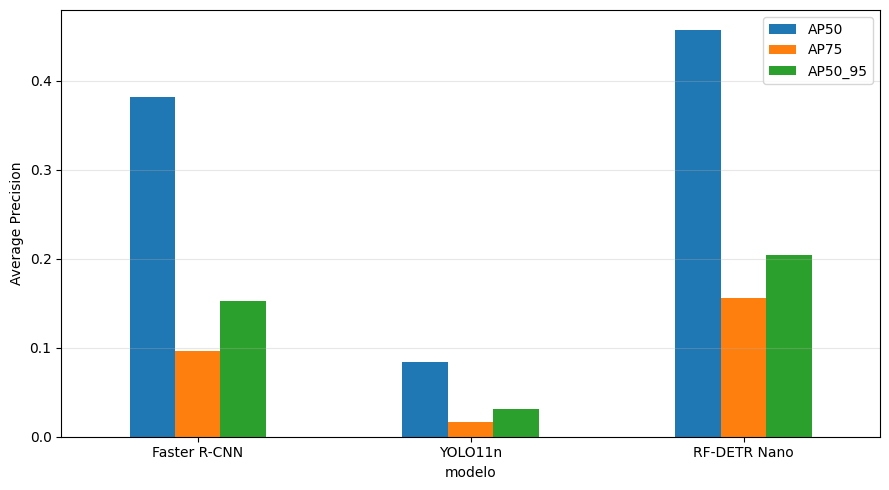

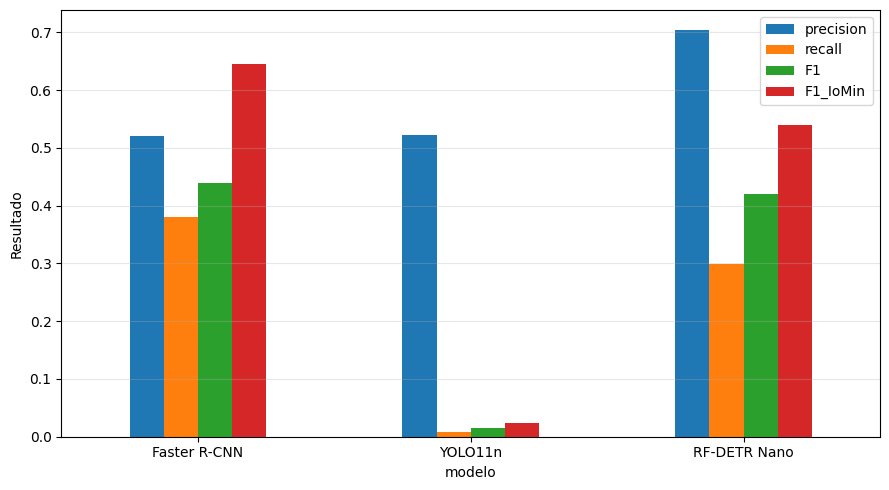

Resultados guardados: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1


In [ ]:
ax = resultados.set_index("modelo")[["AP50", "AP75", "AP50_95"]].plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("Average Precision")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_PRED / "comparacion_ap.png", dpi=180, bbox_inches="tight")
plt.show()

ax = resultados.set_index("modelo")[["precision", "recall", "F1", "F1_IoMin"]].plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("Resultado")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_PRED / "comparacion_precision_recall_f1.png", dpi=180, bbox_inches="tight")
plt.show()

print("Resultados guardados:", DIR_E7)

## Conclusiones

La evaluación comparativa permitió analizar el desempeño de Faster R-CNN + MobileNetV3, YOLO11n y RF-DETR Nano en la localización de eventos acústicos de aves. Se utilizaron 8.113 ventanas positivas de validación y 20.419 anotaciones por conjunto, calculando métricas de detección mediante un procedimiento común.

RF-DETR Nano obtuvo los mejores resultados en las métricas principales de localización, con un AP50 de 0.4566, AP75 de 0.1554 y AP50:95 de 0.2042. Faster R-CNN presentó un desempeño intermedio, mientras que YOLO11n obtuvo los valores más bajos. Estos resultados posicionan a RF-DETR Nano como el candidato principal para continuar el desarrollo del sistema.

El análisis de precisión, recall y F1 evidenció la influencia del umbral de confianza. Faster R-CNN alcanzó el mayor F1 con un umbral fijo de 0.5 (0.4392), mientras que RF-DETR Nano obtuvo el mayor F1 al seleccionar su umbral sobre validación (0.4892). Esto demuestra que la elección del detector debe considerar tanto la capacidad de localización como el equilibrio entre falsos positivos y eventos omitidos.

Los valores de AP75, inferiores a los de AP50 en las tres arquitecturas, indican que la delimitación precisa de las vocalizaciones sigue siendo una dificultad importante. La evaluación con IoMin complementó este análisis al considerar una medida de solapamiento menos restrictiva para determinadas geometrías de las cajas.

Los resultados corresponden exclusivamente a validación sobre ventanas positivas. Aunque se aplicó un evaluador común, quedan pendientes la correspondencia exacta de las anotaciones por ventana, la evaluación de regiones sin eventos anotados y la consolidación de detecciones entre ventanas solapadas. Por tanto, los resultados permiten seleccionar provisionalmente una arquitectura, pero no establecer todavía su rendimiento operativo definitivo.

Se propone continuar con RF-DETR Nano como detector principal, manteniendo la evaluación sobre el conjunto de prueba reservado para la fase final de integración y validación del sistema.

## Finalizar

In [ ]:
from google.colab import runtime

drive.flush_and_unmount()
runtime.unassign()

## Evaluacion operativa de RF-DETR Nano

Evaluamos el detector seleccionado sobre todas las ventanas de validacion, incluyendo aquellas sin eventos anotados. El objetivo es estimar recall y falsos positivos por hora de audio para determinar si se justifica un entrenamiento adicional con ventanas negativas.

### Preparar datos

In [1]:
%pip -q install "kagglehub==1.0.3"

In [2]:
from pathlib import Path
from google.colab import drive
import numpy as np
import pandas as pd
import kagglehub

drive.mount("/content/drive")

BASE_LOCAL = Path("/content/proyecto_aves")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_E3 = BASE_DRIVE / "experiments/detector/E3_RFDETR_Nano/final_v1"
DIR_E7 = BASE_DRIVE / "experiments/detector/E4_Comparacion_v1"
DIR_OPERATIVA = DIR_E7 / "evaluacion_operativa_v1"
DIR_OPERATIVA.mkdir(parents=True, exist_ok=True)

DATASET = "santiagocorrea802/dataset-proyecto"
SPLIT = pd.read_csv(BASE_DRIVE / "splits/recording_split_seed0.csv")

def leer_manifest(nombre):
    ruta = f"DATASET_PROYECTO/metadata/{nombre}"
    archivo = kagglehub.dataset_download(DATASET, path=ruta, output_dir=str(BASE_LOCAL))
    return pd.read_csv(archivo)

master = leer_manifest("master_manifest.csv")
recordings = leer_manifest("recordings_manifest.csv")
detector = leer_manifest("detector_manifest.csv")

catalogo = (SPLIT.loc[SPLIT["split"] == "validation", ["recording_uid", "dataset", "split"]].merge(recordings[["recording_uid", "duration_sec"]],
                                                                                                   on="recording_uid",
                                                                                                   validate="one_to_one").merge(master[["recording_uid", "normalized_path"]].drop_duplicates(),
                                                                                                                                on="recording_uid", validate="one_to_one"))

eventos = detector.merge(catalogo[["recording_uid", "duration_sec"]], on="recording_uid", validate="many_to_one")
eventos["t_max"] = np.minimum(eventos["t_max"], eventos["duration_sec"])

print("Grabaciones validation:", len(catalogo))
print("Eventos anotados:", len(eventos))
print("Horas de audio:", round(catalogo["duration_sec"].sum() / 3600, 2))

Mounted at /content/drive


100%|██████████| 16.8M/16.8M [00:00<00:00, 24.8MB/s]


100%|██████████| 253k/253k [00:00<00:00, 1.13MB/s]


100%|██████████| 10.8M/10.8M [00:00<00:00, 19.3MB/s]


Grabaciones validation: 152
Eventos anotados: 6614
Horas de audio: 20.13


### Construir ventanas

In [3]:
FS, VENTANA_S, SALTO_S = 32000, 8, 4
TAM, SALTO = FS * VENTANA_S, FS * SALTO_S

def inicios_ventanas(n):
    if n < TAM:
        return [0]

    ultimo = n - TAM
    inicios = list(range(0, ultimo + 1, SALTO))

    if inicios[-1] != ultimo:
        diferencia = ultimo - inicios[-1]
        if len(inicios) > 1 and diferencia <= SALTO / 2 and ultimo - inicios[-2] <= TAM:
            inicios[-1] = ultimo
        else:
            inicios.append(ultimo)

    return inicios

registros = []
for grabacion in catalogo.itertuples(index=False):
    n = round(grabacion.duration_sec * FS)
    for vid, inicio in enumerate(inicios_ventanas(n)):
        registros.append({
            "recording_uid": grabacion.recording_uid,
            "ventana_id": vid,
            "normalized_path": grabacion.normalized_path,
            "inicio_muestra": inicio,
            "inicio_s": inicio / FS,
            "fin_s": (inicio + TAM) / FS
        })

indice = pd.DataFrame(registros)
por_audio = {uid: grupo.reset_index(drop=True) for uid, grupo in indice.groupby("recording_uid", sort=False)}
positivas = set()

for evento in eventos.itertuples(index=False):
    grupo = por_audio[evento.recording_uid]
    primero = np.searchsorted(grupo["fin_s"].to_numpy(), evento.t_min, side="right")
    ultimo = np.searchsorted(grupo["inicio_s"].to_numpy(), evento.t_max, side="left")

    for ventana in grupo.iloc[primero:ultimo].itertuples(index=False):
        if min(evento.t_max, ventana.fin_s) > max(evento.t_min, ventana.inicio_s):
            positivas.add((evento.recording_uid, ventana.ventana_id))

indice["con_anotacion"] = [
    (fila.recording_uid, fila.ventana_id) in positivas
    for fila in indice.itertuples(index=False)
]

indice.to_csv(DIR_OPERATIVA / "ventanas_validation.csv", index=False)
catalogo.to_csv(DIR_OPERATIVA / "grabaciones_validation.csv", index=False)
eventos.to_csv(DIR_OPERATIVA / "eventos_validation.csv", index=False)

print("Ventanas totales:", len(indice))
print("Ventanas positivas:", int(indice["con_anotacion"].sum()))
print("Ventanas sin anotaciones:", int((~indice["con_anotacion"]).sum()))
print("Indice guardado:", DIR_OPERATIVA)

Ventanas totales: 17962
Ventanas positivas: 8113
Ventanas sin anotaciones: 9849
Indice guardado: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1/evaluacion_operativa_v1


In [4]:
import hashlib

indice["archivo"] = [
    hashlib.sha256(f"{uid}|{vid}".encode()).hexdigest()[:20]
    for uid, vid in zip(indice["recording_uid"], indice["ventana_id"])
]

indice.to_csv(DIR_OPERATIVA / "ventanas_validation.csv", index=False)

print("Ventanas totales:", len(indice))
print("Ventanas positivas:", indice["con_anotacion"].sum())
print("Ventanas sin anotaciones:", (~indice["con_anotacion"]).sum())
print("Indice guardado")

Ventanas totales: 17962
Ventanas positivas: 8113
Ventanas sin anotaciones: 9849
Indice guardado


### Reconstruir y verificar espectogramas

In [5]:
import soundfile as sf
from scipy.signal import stft
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PNG = "santiagocorrea802/dataset-yolo11n-aves"

positivas = indice.loc[indice["con_anotacion"]].sort_values("archivo").reset_index(drop=True).copy()
positivas["parte"] = np.searchsorted([858, 3858, 6858], np.arange(len(positivas)), side="right") + 13

muestras = positivas.merge(catalogo[["recording_uid", "duration_sec"]], on="recording_uid")
fila = muestras.sort_values("duration_sec").iloc[0]

ruta_png = f"yolo11n_parte_{int(fila.parte):02d}/images/val/{fila.archivo}.png"
ruta_audio = str(fila.normalized_path).replace("\\", "/")
if not ruta_audio.startswith("DATASET_PROYECTO/"):
    ruta_audio = f"DATASET_PROYECTO/{ruta_audio}"

png_original = Path(kagglehub.dataset_download(DATASET_PNG, path=ruta_png, output_dir=str(BASE_LOCAL)))
audio_original = Path(kagglehub.dataset_download(DATASET, path=ruta_audio, output_dir=str(BASE_LOCAL)))

with Image.open(png_original) as imagen:
    modo_original = imagen.mode
    referencia = np.asarray(imagen.convert("RGB"), dtype=np.uint8)

with sf.SoundFile(audio_original) as archivo:
    archivo.seek(int(fila.inicio_muestra))
    audio = archivo.read(FS * VENTANA_S, dtype="float32")

if len(audio) < FS * VENTANA_S:
    audio = np.pad(audio, (0, FS * VENTANA_S - len(audio)))

print("Grabacion:", fila.recording_uid)
print("Ventana:", fila.ventana_id)
print("PNG:", referencia.shape, modo_original)
print("Audio:", len(audio), "muestras")

100%|██████████| 382k/382k [00:00<00:00, 1.24MB/s]


100%|██████████| 1.69M/1.69M [00:00<00:00, 4.38MB/s]

Grabacion: WABAD-CO::bre_20071210_060500
Ventana: 13
PNG: (513, 997, 3) L
Audio: 256000 muestras


gris_truncado: MAE=0.4945, pixeles iguales=50.55%
gris_redondeado: MAE=0.0000, pixeles iguales=100.00%
magma: MAE=51.9076, pixeles iguales=0.47%
inferno: MAE=62.0963, pixeles iguales=0.08%
viridis: MAE=47.0912, pixeles iguales=0.50%
plasma: MAE=58.1654, pixeles iguales=0.05%


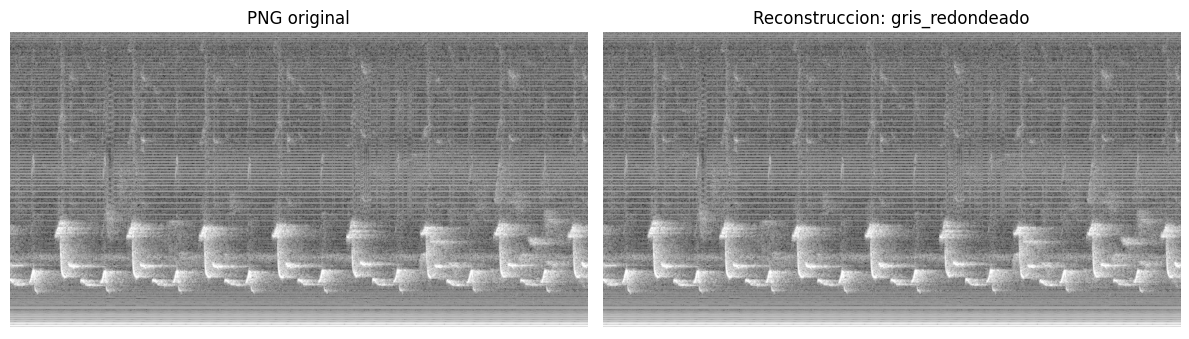

Mejor conversion: gris_redondeado
Error medio: 0.0


In [6]:
def generar_espectrograma(audio):
    _, _, z = stft(audio, fs=32000, nperseg=1024, noverlap=768, boundary=None)
    db = 20 * np.log10(np.maximum(np.abs(z), 1e-8))
    vmax = np.percentile(db, 99)
    return np.flipud(np.clip((db - (vmax - 80)) / 80, 0, 1))

espectrograma = generar_espectrograma(audio)

gris = np.clip(espectrograma * 255, 0, 255)
variantes = {
    "gris_truncado": np.repeat(gris.astype(np.uint8)[:, :, None], 3, axis=2),
    "gris_redondeado": np.repeat(np.rint(gris).astype(np.uint8)[:, :, None], 3, axis=2)
}

for nombre in ("magma", "inferno", "viridis", "plasma"):
    colores = plt.get_cmap(nombre)(espectrograma)[:, :, :3] * 255
    variantes[nombre] = colores.astype(np.uint8)

errores = {}
for nombre, imagen in variantes.items():
    diferencia = np.abs(imagen.astype(np.int16) - referencia.astype(np.int16))
    errores[nombre] = diferencia.mean()
    print(f"{nombre}: MAE={diferencia.mean():.4f}, pixeles iguales={(diferencia == 0).mean():.2%}")

mejor = min(errores, key=errores.get)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(referencia)
ax[0].set_title("PNG original")
ax[1].imshow(variantes[mejor])
ax[1].set_title(f"Reconstruccion: {mejor}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

print("Mejor conversion:", mejor)
print("Error medio:", round(errores[mejor], 4))

### Configuración y recuperación de predicciones

In [7]:
%pip -q install "rfdetr==1.12.0"

import gc
import json
import torch
from tqdm.auto import tqdm
from rfdetr import RFDETRNano

def imagen_desde_audio(audio):
    _, _, z = stft(audio, fs=32000, nperseg=1024, noverlap=768, boundary=None)
    db = 20 * np.log10(np.maximum(np.abs(z), 1e-8))
    vmax = np.percentile(db, 99)
    espectrograma = np.flipud(np.clip((db - (vmax - 80)) / 80, 0, 1))
    matriz = np.rint(espectrograma * 255).astype(np.uint8)
    return Image.fromarray(matriz, mode="L").convert("RGB")

def cajas_eventos(grupo):
    y_min = 1 - np.clip(grupo["f_max"].to_numpy(np.float32) / 16000.0, 0, 1)
    y_max = 1 - np.clip(grupo["f_min"].to_numpy(np.float32) / 16000.0, 0, 1)
    return np.column_stack([
        grupo["t_min"].to_numpy(np.float32),
        y_min.astype(np.float32),
        grupo["t_max"].to_numpy(np.float32),
        y_max.astype(np.float32)
    ])

HORAS_AUDIO = catalogo["duration_sec"].sum() / 3600
CONF_MIN = 0.05
MAX_DETECCIONES = 100
BLOQUE = 128

DIR_NEG = DIR_OPERATIVA / "predicciones_negativas_rfdetr"
DIR_NEG.mkdir(parents=True, exist_ok=True)

print("Horas de audio:", round(HORAS_AUDIO, 2))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Horas de audio: 20.13


In [8]:
def hash_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

hash_rfdetr = hash_archivo(DIR_E3 / "checkpoint_best_total.pth")
candidatos = []

for ruta in sorted((DIR_E7 / "predicciones").glob("*/protocolo.json")):
    protocolo = json.loads(ruta.read_text(encoding="utf-8"))
    if protocolo.get("rfdetr") == hash_rfdetr:
        candidatos.append(ruta.parent)

if not candidatos:
    raise FileNotFoundError("No se encontraron predicciones positivas previas de RF-DETR Nano")

DIR_POS = candidatos[-1] / "rfdetr_nano"
pred_positivas = []

for archivo in sorted(DIR_POS.glob("*.pt")):
    pred_positivas.extend(torch.load(archivo, map_location="cpu", weights_only=True))

if len(pred_positivas) != len(positivas):
    raise ValueError("La cantidad de predicciones positivas no coincide con las ventanas positivas")

positivas = positivas.copy()
positivas["pred"] = pred_positivas

print("Carpeta de predicciones positivas:", DIR_POS)
print("Ventanas positivas cargadas:", len(positivas))

Carpeta de predicciones positivas: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1/predicciones/14851be08eb33c92/rfdetr_nano
Ventanas positivas cargadas: 8113


### Inferencia sobre ventanas sin anotaciones

In [9]:
negativas = indice.loc[~indice["con_anotacion"]].sort_values(["recording_uid", "ventana_id"]).reset_index(drop=True).copy()

configuracion = json.loads((DIR_E3 / "configuracion.json").read_text(encoding="utf-8"))
modelo = RFDETRNano(pretrain_weights=str(DIR_E3 / "checkpoint_best_total.pth"), num_classes=1, resolution=int(configuracion["resolution"]))

def ruta_audio_local(normalized_path):
    ruta = str(normalized_path).replace("\\", "/")
    if not ruta.startswith("DATASET_PROYECTO/"):
        ruta = f"DATASET_PROYECTO/{ruta}"
    return Path(kagglehub.dataset_download(DATASET, path=ruta, output_dir=str(BASE_LOCAL)))

def agregar_predicciones(predicciones, imagenes, salidas):
    for imagen, salida in zip(imagenes, salidas):
        ancho, alto = imagen.size
        escala = np.asarray([ancho, alto, ancho, alto], dtype=np.float32)
        cajas = np.asarray(salida.xyxy, dtype=np.float32).reshape(-1, 4) / escala
        scores = np.asarray(salida.confidence, dtype=np.float32).reshape(-1)
        idx = np.argsort(-scores)[:MAX_DETECCIONES]
        predicciones.append({
            "boxes": torch.from_numpy(cajas[idx].copy()),
            "scores": torch.from_numpy(scores[idx].copy())
        })

for inicio in tqdm(range(0, len(negativas), BLOQUE), desc="RF-DETR negativas"):
    archivo = DIR_NEG / f"{inicio:05d}.pt"
    if archivo.is_file():
        continue

    bloque = negativas.iloc[inicio:inicio + BLOQUE]
    predicciones = []

    for _, grupo in bloque.groupby("recording_uid", sort=False):
        ruta_audio = ruta_audio_local(grupo["normalized_path"].iloc[0])

        with sf.SoundFile(ruta_audio) as archivo_audio:
            imagenes = []

            for fila in grupo.itertuples(index=False):
                archivo_audio.seek(int(fila.inicio_muestra))
                audio = archivo_audio.read(FS * VENTANA_S, dtype="float32")

                if len(audio) < FS * VENTANA_S:
                    audio = np.pad(audio, (0, FS * VENTANA_S - len(audio)))

                imagenes.append(imagen_desde_audio(audio))

                if len(imagenes) == 2:
                    salidas = modelo.predict(imagenes, threshold=CONF_MIN)
                    agregar_predicciones(predicciones, imagenes, salidas)
                    imagenes = []

            if imagenes:
                salidas = modelo.predict(imagenes, threshold=CONF_MIN)
                agregar_predicciones(predicciones, imagenes, salidas)

    temporal = archivo.with_suffix(".tmp")
    torch.save(predicciones, temporal)
    temporal.replace(archivo)

print("Predicciones negativas completas")
del modelo
gc.collect()

RF-DETR negativas:   0%|          | 0/77 [00:00<?, ?it/s]


  0%|          | 0.00/18.5M [00:00<?, ?B/s]
  5%|▌         | 1.00M/18.5M [00:00<00:06, 3.00MB/s]
 22%|██▏       | 4.00M/18.5M [00:00<00:01, 10.6MB/s]
 60%|█████▉    | 11.0M/18.5M [00:00<00:00, 25.8MB/s]
100%|██████████| 18.5M/18.5M [00:00<00:00, 25.5MB/s]
/tmp/ipykernel_918/2433537594.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(matriz, mode="L").convert("RGB")
[2026-11-17 20:36:40] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).
/tmp/ipykernel_918/2433537594.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(matriz, mode="L").convert("RGB")



  0%|          | 0.00/15.2M [00:00<?, ?B/s]
  7%|▋         | 1.00M/15.2M [00:00<00:05, 2.94MB/s]
 26%|██▋       | 4.00M/15.2M [00:00<00:01, 10.4MB/s]
100%|██████████| 15.2M/15.2M [00:00<00:00, 23.9MB/s]



  0%|          | 0.00/17.5M [00:00<?, ?B/s]
  6%|▌         | 1.00M/17.5M [00:00<00:06, 2.51MB/s]
 17%|█▋        | 3.00M/17.5M [00:00<00:02, 6.94MB/s]
 46%|████▌     | 8.00M/17.5M [00:00<00:00, 18.5MB/s]
 63%|██████▎   | 11.0M/17.5M [00:00<00:00, 15.6MB/s]
100%|██████████| 17.5M/17.5M [00:01<00:00, 16.5MB/s]
/tmp/ipykernel_918/2433537594.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(matriz, mode="L").convert("RGB")



  0%|          | 0.00/17.7M [00:00<?, ?B/s]
  6%|▌         | 1.00M/17.7M [00:00<00:05, 2.95MB/s]
 23%|██▎       | 4.00M/17.7M [00:00<00:01, 10.4MB/s]
 62%|██████▏   | 11.0M/17.7M [00:00<00:00, 24.7MB/s]
100%|██████████| 17.7M/17.7M [00:00<00:00, 25.0MB/s]
/tmp/ipykernel_918/2433537594.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(matriz, mode="L").convert("RGB")



  0%|          | 0.00/17.8M [00:00<?, ?B/s]
  6%|▌         | 1.00M/17.8M [00:00<00:07, 2.43MB/s]
 17%|█▋        | 3.00M/17.8M [00:00<00:02, 6.59MB/s]
 45%|████▍     | 8.00M/17.8M [00:00<00:00, 17.5MB/s]
100%|██████████| 17.8M/17.8M [00:00<00:00, 22.2MB/s]


... (46 outputs left out)


  0%|          | 0.00/2.57M [00:00<?, ?B/s]
100%|██████████| 2.57M/2.57M [00:00<00:00, 6.00MB/s]



  0%|          | 0.00/2.36M [00:00<?, ?B/s]
100%|██████████| 2.36M/2.36M [00:00<00:00, 5.74MB/s]


Predicciones negativas completas


545

### Consolidación de detecciones

In [10]:
pred_negativas = []

for archivo in sorted(DIR_NEG.glob("*.pt")):
    pred_negativas.extend(torch.load(archivo, map_location="cpu", weights_only=True))

if len(pred_negativas) != len(negativas):
    raise ValueError("La cantidad de predicciones negativas no coincide con las ventanas sin anotaciones")

negativas = negativas.copy()
negativas["pred"] = pred_negativas
columnas_base = ["recording_uid", "ventana_id", "inicio_s", "fin_s", "con_anotacion", "pred"]
todas = pd.concat([positivas[columnas_base], negativas[columnas_base] ],
                  ignore_index=True).sort_values(["recording_uid", "ventana_id"]).reset_index(drop=True)

def proyectar_predicciones(tabla):
    salida = {}

    for fila in tabla.itertuples(index=False):
        pred = fila.pred
        cajas = pred["boxes"].numpy()
        scores = pred["scores"].numpy()

        if len(cajas) == 0:
            continue

        proyectadas = np.column_stack([
            fila.inicio_s + cajas[:, 0] * VENTANA_S,
            cajas[:, 1],
            fila.inicio_s + cajas[:, 2] * VENTANA_S,
            cajas[:, 3],
            scores
        ]).astype(np.float32)

        salida.setdefault(fila.recording_uid, []).append(proyectadas)

    for uid in list(salida):
        salida[uid] = np.concatenate(salida[uid], axis=0)

    return salida

gt = {uid: cajas_eventos(grupo) for uid, grupo in eventos.groupby("recording_uid", sort=False)}
pred = proyectar_predicciones(todas)

print("Ventanas positivas:", len(positivas))
print("Ventanas negativas:", len(negativas))
print("Ventanas totales:", len(todas))
print("Grabaciones:", len(gt))

Ventanas positivas: 8113
Ventanas negativas: 9849
Ventanas totales: 17962
Grabaciones: 152


In [11]:
def solapamiento(a, b, tipo):
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)), dtype=np.float32)

    inter = np.maximum(np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2]), 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)

    if tipo == "iou":
        divisor = area_a[:, None] + area_b[None, :] - inter
    else:
        divisor = np.minimum(area_a[:, None], area_b[None, :])

    return np.divide(inter, divisor, out=np.zeros_like(inter), where=divisor > 0)

def fusionar(cajas_scores, tipo="iou", umbral=0.5):
    if len(cajas_scores) == 0:
        return np.empty((0, 5), dtype=np.float32)

    orden = np.argsort(-cajas_scores[:, 4], kind="stable")
    conservadas = []

    while len(orden):
        i = orden[0]
        conservadas.append(i)

        if len(orden) == 1:
            break

        resto = orden[1:]
        sup = solapamiento(cajas_scores[resto, :4], cajas_scores[i:i + 1, :4], tipo).reshape(-1)
        orden = resto[sup < umbral]

    return cajas_scores[conservadas]

pred_iou = {uid: fusionar(cajas, "iou", 0.5) for uid, cajas in pred.items()}
pred_iomin = {uid: fusionar(cajas, "iomin", 0.5) for uid, cajas in pred.items()}
print("Detecciones antes de fusion:", sum(len(x) for x in pred.values()))
print("Detecciones despues de fusion IoU:", sum(len(x) for x in pred_iou.values()))
print("Detecciones despues de fusion IoMin:", sum(len(x) for x in pred_iomin.values()))

Detecciones antes de fusion: 927444
Detecciones despues de fusion IoU: 409238
Detecciones despues de fusion IoMin: 98197


### Evaluación operativa: Recall y FP/h

In [14]:
def evaluar_operativa(predicciones, objetivos, horas_audio, tipo):
    total_gt = sum(len(x) for x in objetivos.values())
    umbrales = np.unique(np.r_[np.linspace(CONF_MIN, 0.99, 95), 0.5])
    filas = []

    for umbral in tqdm(umbrales, desc=f"Operativa {tipo}"):
        tp = 0
        fp = 0

        for uid, gt_uid in objetivos.items():
            det_uid = predicciones.get(uid, np.empty((0, 5), dtype=np.float32))
            det_uid = det_uid[det_uid[:, 4] >= umbral]
            usados = set()

            for i in np.argsort(-det_uid[:, 4], kind="stable"):
                candidatos = [j for j in range(len(gt_uid)) if j not in usados]

                if not candidatos:
                    fp += 1
                    continue

                sup = solapamiento(det_uid[i:i + 1, :4], gt_uid[candidatos], tipo).reshape(-1)
                j = int(sup.argmax()) if len(sup) else -1

                if j >= 0 and sup[j] >= 0.5:
                    usados.add(candidatos[j])
                    tp += 1
                else:
                    fp += 1

        fn = total_gt - tp
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / total_gt if total_gt else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

        filas.append({
            "criterio": tipo,
            "umbral": float(umbral),
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "fp_h": fp / horas_audio
        })

    return pd.DataFrame(filas)

curva_iou = evaluar_operativa(pred_iou, gt, HORAS_AUDIO, "iou")
curva_iomin = evaluar_operativa(pred_iou, gt, HORAS_AUDIO, "iomin")
curvas = pd.concat([curva_iou, curva_iomin], ignore_index=True)
curvas.to_csv(DIR_OPERATIVA / "curva_recall_fp_h_rfdetr.csv", index=False)

resumen = pd.concat([
    curva_iou.loc[np.isclose(curva_iou["umbral"], 0.5)].assign(escenario="umbral_0.5"),
    curva_iou.loc[[curva_iou["f1"].idxmax()]].assign(escenario="mejor_f1"),
    curva_iomin.loc[np.isclose(curva_iomin["umbral"], 0.5)].assign(escenario="umbral_0.5"),
    curva_iomin.loc[[curva_iomin["f1"].idxmax()]].assign(escenario="mejor_f1")
], ignore_index=True)

resumen.to_csv(DIR_OPERATIVA / "resumen_operativo_rfdetr.csv", index=False)
display(resumen[["criterio", "escenario", "umbral", "recall", "precision", "f1", "fp_h", "tp", "fp", "fn"]].round(4))

Operativa iou:   0%|          | 0/95 [00:00<?, ?it/s]

Operativa iomin:   0%|          | 0/95 [00:00<?, ?it/s]

,criterio,escenario,umbral,recall,precision,f1,fp_h,tp,fp,fn
0,iou,umbral_0.5,0.50,0.2923,0.2382,0.2625,307.0418,1933,6181,4681
1,iou,mejor_f1,0.44,0.3524,0.2194,0.2704,412.0550,2331,8295,4283
2,iomin,umbral_0.5,0.50,0.5290,0.4312,0.4751,229.2506,3499,4615,3115
3,iomin,mejor_f1,0.47,0.5783,0.4134,0.4821,269.6364,3825,5428,2789


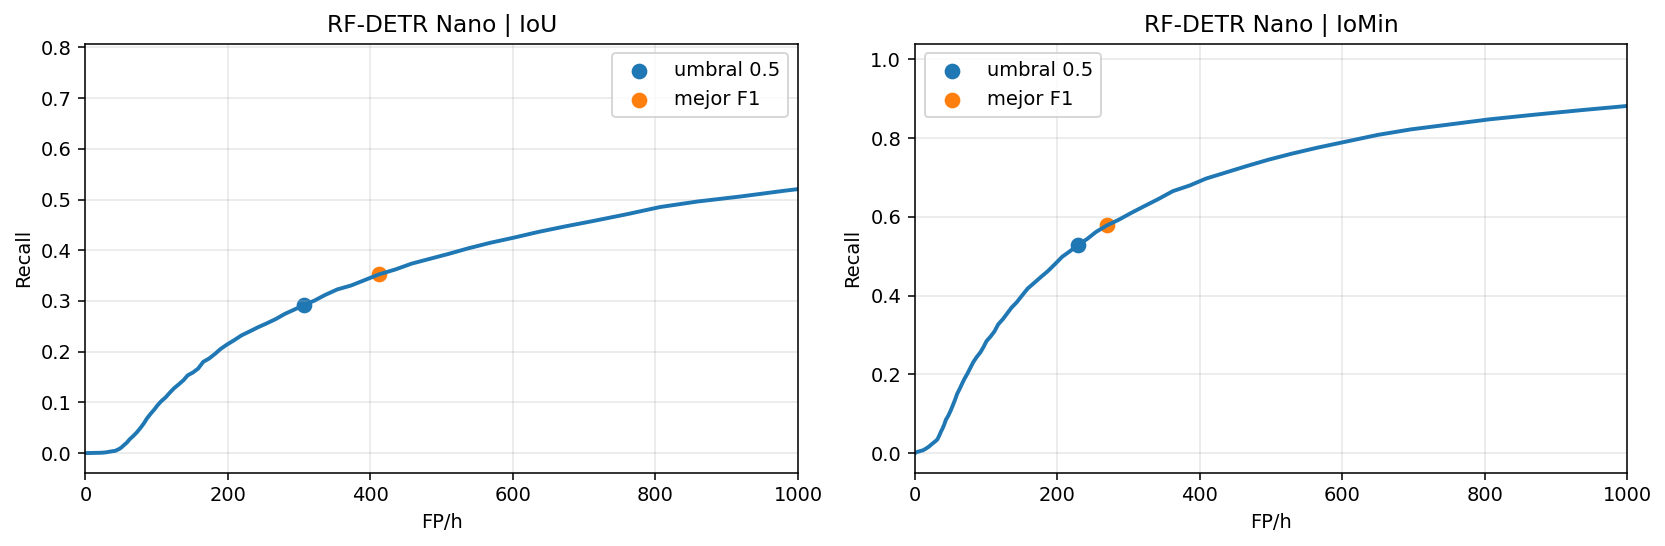

Resultados guardados en: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1/evaluacion_operativa_v1


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), dpi=140)

for eje, curva, titulo in zip(ax, [curva_iou, curva_iomin], ["IoU", "IoMin"]):
    eje.plot(curva["fp_h"], curva["recall"], lw=2)
    fila_05 = curva.loc[np.isclose(curva["umbral"], 0.5)].iloc[0]
    fila_f1 = curva.loc[curva["f1"].idxmax()]
    eje.set_xlim(0, 1000)
    eje.scatter([fila_05["fp_h"]], [fila_05["recall"]], s=50, label="umbral 0.5")
    eje.scatter([fila_f1["fp_h"]], [fila_f1["recall"]], s=50, label="mejor F1")
    eje.set_title(f"RF-DETR Nano | {titulo}")
    eje.set_xlabel("FP/h")
    eje.set_ylabel("Recall")
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.savefig(DIR_OPERATIVA / "curva_recall_fp_h_rfdetr.png", dpi=180, bbox_inches="tight")
plt.show()

print("Resultados guardados en:", DIR_OPERATIVA)

In [20]:
def resumen_ventanas(tabla):
    conteos = tabla["pred"].map(lambda p: int((p["scores"] >= 0.5).sum()))
    return {
        "ventanas": len(tabla),
        "ventanas_con_detecciones": int((conteos > 0).sum()),
        "detecciones_sin_fusion": int(conteos.sum()),
        "porcentaje_activas": round(100 * (conteos > 0).mean(), 2)
    }

analisis = pd.DataFrame({"Con anotaciones": resumen_ventanas(positivas), "Sin anotaciones": resumen_ventanas(negativas)}).T

analisis.to_csv(DIR_OPERATIVA / "analisis_ventanas_rfdetr.csv")
display(analisis)

,ventanas,ventanas_con_detecciones,detecciones_sin_fusion,porcentaje_activas
Con anotaciones,8113.0,5714.0,8671.0,70.43
Sin anotaciones,9849.0,1403.0,1450.0,14.25


In [22]:
torch.save({
    "gt": {uid: torch.from_numpy(cajas) for uid, cajas in gt.items()},
    "pred_iou": {uid: torch.from_numpy(cajas) for uid, cajas in pred_iou.items()}
}, DIR_OPERATIVA / "datos_analisis.pt")

print("Datos de analisis guardados")

Datos de analisis guardados


### Detectemos a que se deben los errores

In [ ]:
import numpy as np

def solapamiento(a, b, tipo):
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)), dtype=np.float32)

    inter = np.maximum(np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2]), 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)

    if tipo == "iou":
        divisor = area_a[:, None] + area_b[None, :] - inter
    else:
        divisor = np.minimum(area_a[:, None], area_b[None, :])
    return np.divide(inter, divisor, out=np.zeros_like(inter), where=divisor > 0)

print("Funcion de solapamiento disponible")

In [1]:
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

drive.mount("/content/drive")

DIR_OPERATIVA = Path("/content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1/evaluacion_operativa_v1")

datos = torch.load(DIR_OPERATIVA / "datos_analisis.pt", map_location="cpu", weights_only=True)
gt = {uid: cajas.numpy() for uid, cajas in datos["gt"].items()}
pred_iou = {uid: cajas.numpy() for uid, cajas in datos["pred_iou"].items()}

catalogo = pd.read_csv(DIR_OPERATIVA / "grabaciones_validation.csv")
eventos = pd.read_csv(DIR_OPERATIVA / "eventos_validation.csv")
falsos_positivos = pd.read_csv(DIR_OPERATIVA / "falsos_positivos.csv")
resumen_fuentes = pd.read_csv(DIR_OPERATIVA / "errores_por_fuente.csv")

display(resumen_fuentes.round(4))

Mounted at /content/drive


,dataset,grabaciones,horas,eventos,tp,fp,fn,recall,fp_h
0,Col-CR,5,4.9997,1055,294,1408,761,0.2787,281.6167
1,Peru,3,3.0000,1921,494,2912,1427,0.2572,970.6667
2,PteroSet,85,11.1478,2253,713,1470,1540,0.3165,131.8648
3,WABAD-CO,59,0.9833,1385,432,391,953,0.3119,397.6291


In [7]:
filas, falsos_positivos = [], []

for grabacion in catalogo.itertuples(index=False):
    uid = grabacion.recording_uid
    reales = gt.get(uid, np.empty((0, 4), dtype=np.float32))
    detecciones = pred_iou.get(uid, np.empty((0, 5), dtype=np.float32))
    detecciones = detecciones[detecciones[:, 4] >= 0.5]
    usados = set()
    tp, fp = 0, 0

    for i in np.argsort(-detecciones[:, 4], kind="stable"):
        disponibles = [j for j in range(len(reales)) if j not in usados]
        acierto = False

        if disponibles:
            sup = solapamiento(detecciones[i:i+1, :4], reales[disponibles], "iou").ravel()
            j = int(sup.argmax())
            if sup[j] >= 0.5:
                usados.add(disponibles[j])
                tp += 1
                acierto = True

        if not acierto:
            fp += 1
            caja = detecciones[i]
            falsos_positivos.append({
                "dataset": grabacion.dataset,
                "recording_uid": uid,
                "t_min": float(caja[0]),
                "t_max": float(caja[2]),
                "f_min": float((1 - caja[3]) * 16000),
                "f_max": float((1 - caja[1]) * 16000),
                "confianza": float(caja[4])
            })

    filas.append({
        "dataset": grabacion.dataset,
        "recording_uid": uid,
        "horas": grabacion.duration_sec / 3600,
        "eventos": len(reales),
        "tp": tp,
        "fp": fp,
        "fn": len(reales) - tp
    })

detalle = pd.DataFrame(filas)
resumen_fuentes = detalle.groupby("dataset", as_index=False).agg(grabaciones=("recording_uid", "count"), horas=("horas", "sum"), eventos=("eventos", "sum"), tp=("tp", "sum"), fp=("fp", "sum"), fn=("fn", "sum"))

resumen_fuentes["recall"] = resumen_fuentes["tp"] / resumen_fuentes["eventos"]
resumen_fuentes["fp_h"] = resumen_fuentes["fp"] / resumen_fuentes["horas"]

falsos_positivos = pd.DataFrame(falsos_positivos).sort_values("confianza", ascending=False)
resumen_fuentes.to_csv(DIR_OPERATIVA / "errores_por_fuente.csv", index=False)
falsos_positivos.to_csv(DIR_OPERATIVA / "falsos_positivos.csv", index=False)

display(resumen_fuentes.round(4))
print("Falsos positivos:", len(falsos_positivos))
display(falsos_positivos.head(10))

,dataset,grabaciones,horas,eventos,tp,fp,fn,recall,fp_h
0,Col-CR,5,4.9997,1055,294,1408,761,0.2787,281.6167
1,Peru,3,3.0000,1921,494,2912,1427,0.2572,970.6667
2,PteroSet,85,11.1478,2253,713,1470,1540,0.3165,131.8648
3,WABAD-CO,59,0.9833,1385,432,391,953,0.3119,397.6291


Falsos positivos: 6181


,dataset,recording_uid,t_min,t_max,f_min,f_max,confianza
1408,Peru,Peru::per_002_s02_20190116_100007z,1712.005005,1720.000000,2719.468018,4718.955078,0.947279
1409,Peru,Peru::per_002_s02_20190116_100007z,2672.000000,2680.000000,2706.994141,4702.801758,0.946829
1410,Peru,Peru::per_002_s02_20190116_100007z,1332.000854,1340.000000,2797.657959,4797.852539,0.946404
1411,Peru,Peru::per_002_s02_20190116_100007z,1180.006592,1187.997314,2802.753418,4843.669922,0.945829
1412,Peru,Peru::per_002_s02_20190116_100007z,2640.000000,2647.999268,2653.909668,4642.870117,0.945697
1413,Peru,Peru::per_002_s02_20190116_100007z,1160.005127,1168.000000,2752.986816,4914.106445,0.945465
1414,Peru,Peru::per_002_s02_20190116_100007z,2124.000000,2132.000000,2637.757324,4722.998535,0.945252
1415,Peru,Peru::per_002_s02_20190116_100007z,1460.000488,1468.000000,2712.248779,4769.387207,0.945042
1416,Peru,Peru::per_002_s02_20190116_100007z,2652.001221,2659.995605,2653.876221,4716.132324,0.944781
1417,Peru,Peru::per_002_s02_20190116_100007z,1108.007446,1116.000000,2809.979492,4831.202637,0.944780


### Analisis de grabaciones con mayor cantidad de falsas detecciones

In [8]:
import pandas as pd
from pathlib import Path

DIR_OPERATIVA = Path("/content/drive/MyDrive/Proyecto_Aves/experiments/detector/E4_Comparacion_v1/evaluacion_operativa_v1")
detalle = pd.read_csv(DIR_OPERATIVA / "errores_por_fuente.csv") if False else None
falsos = pd.read_csv(DIR_OPERATIVA / "falsos_positivos.csv")
grabaciones = pd.read_csv(DIR_OPERATIVA / "grabaciones_validation.csv")
resumen = falsos.groupby(["dataset", "recording_uid"]).size().reset_index(name="fp")
resumen = resumen.merge(grabaciones[["recording_uid", "duration_sec"]], on="recording_uid")
resumen["fp_h"] = resumen["fp"] / (resumen["duration_sec"] / 3600)
falsos["duracion_s"] = falsos["t_max"] - falsos["t_min"]
print("Grabaciones con mas falsas detecciones")
display(resumen.sort_values("fp", ascending=False).head(10).round(2))
print("Falsas detecciones que abarcan casi 8 segundos")
display(falsos.assign(caja_completa=falsos["duracion_s"] >= 7.5).groupby("dataset")["caja_completa"].agg(["sum", "count", "mean"]).round(3))

Grabaciones con mas falsas detecciones


,dataset,recording_uid,fp,duration_sec,fp_h
5,Peru,Peru::per_002_s02_20190116_100007z,1500,3600.00,1500.00
6,Peru,Peru::per_010_s04_20190120_100007z,930,3600.00,930.00
1,Col-CR,Col-CR::nes_010_s01_20191003_053000,761,3600.00,761.00
7,Peru,Peru::per_015_s01_20190131_100007z,482,3600.00,482.00
2,Col-CR,Col-CR::nes_019_s02_20190904_053000,251,3600.00,251.00
4,Col-CR,Col-CR::nes_028_s02_20191004_043000,180,3600.00,180.00
3,Col-CR,Col-CR::nes_020_s02_20190904_053000,118,3600.00,118.00
0,Col-CR,Col-CR::nes_008_s01_20190914_180001,98,3598.93,98.03
89,PteroSet,PteroSet::p5-g022_04-18_tlapse,53,480.00,397.50
88,PteroSet,PteroSet::p5-g022_04-14_tlapse,45,480.00,337.50


Falsas detecciones que abarcan casi 8 segundos


,sum,count,mean
dataset,,,
Col-CR,725,1408,0.515
Peru,2073,2912,0.712
PteroSet,83,1470,0.056
WABAD-CO,52,391,0.133


### Conclusiones de la evaluación operativa

La evaluación de RF-DETR Nano sobre 152 grabaciones completas de validación (20,13 horas) evidenció dificultades para recuperar y delimitar correctamente las vocalizaciones. Con un umbral de confianza de 0,5, obtuvo un recall de 29,23 % utilizando IoU y de 52,90 % utilizando IoMin, con 307,04 y 229,25 falsas detecciones por hora, respectivamente.

Los errores fueron especialmente frecuentes en los datasets de Perú y Col-CR, donde numerosas detecciones abarcaron prácticamente los 8 segundos de una ventana. Esto sugiere problemas de localización y posibles confusiones con sonidos ambientales.

Dado que los detectores se entrenaron únicamente con ventanas que contenían eventos anotados, se realizará un experimento adicional de *fine-tuning* de RF-DETR Nano, incorporando ventanas sin anotaciones del conjunto de entrenamiento. Posteriormente, se comparará el modelo original con el ajustado sobre las mismas grabaciones de validación para determinar si disminuyen las falsas detecciones sin perjudicar significativamente el recall.